<a href="https://colab.research.google.com/github/Rohan46os/Video_gen_model/blob/main/diffusion_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from torch._C import device
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
import math
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
import kagglehub
path = kagglehub.dataset_download("andrewmvd/face-mask-detection")

100%|██████████| 398M/398M [00:08<00:00, 47.1MB/s]

Extracting files...


In [ ]:
path

'/root/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1'

In [ ]:
img1_path = "/kaggle/input/face-mask-detection/images/maksssksksss0.png"

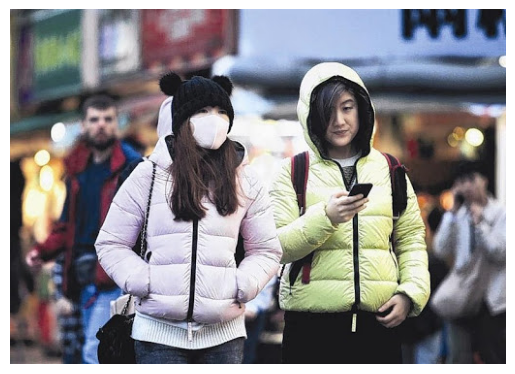

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(img1_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
from tqdm import tqdm
import os
import numpy as np
from PIL import Image

image_folder = "/kaggle/input/face-mask-detection/images"

vectors = []
filenames = []

files = os.listdir(image_folder)

for filename in tqdm(files):
    filepath = os.path.join(image_folder, filename)

    try:
        img = Image.open(filepath).convert("RGB")
        img = img.resize((128, 128))

        img_array = np.array(img, dtype=np.float32) / 255.0
        vectors.append(img_array.flatten())
        filenames.append(filename)

    except:
        pass

vectors = np.array(vectors)

print(vectors.shape)

100%|██████████| 853/853 [00:12<00:00, 65.63it/s]

(853, 49152)


In [ ]:
import torch

X = torch.tensor(vectors, dtype=torch.float32)

# (N, 49152) → (N, 128, 128, 3)
X = X.reshape(-1, 128, 128, 3)

# (N, H, W, C) → (N, C, H, W)
X = X.permute(0, 3, 1, 2)

print(X.shape)

torch.Size([853, 3, 128, 128])


In [ ]:
vectors.shape

(853, 49152)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
dataset

**Now bulding a VAE which will predict MEAN and VARIANCE**

Building a cnn VAE encoder which predicts the mean and variance of all the vectors


In [ ]:
##This is an encoder which encodes input vector into latent space by producing mean and variance

import torch
import torch.nn as nn


class Encoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.encoder = nn.Sequential(
            # [B, 3, 128, 128]
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 128, 32, 32]
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # Produce mean and log-variance
        self.mu = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

        self.logvar = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

    def forward(self, x):
        h = self.encoder(x)

        mu = self.mu(h)
        logvar = self.logvar(h)

        return mu, logvar

In [ ]:
model = Encoder()

x = torch.randn(32, 3, 128, 128)

mu, logvar = model(x)

print("input   :", x.shape) # (32, 49152)
print("mu      :", mu.shape) #(32, 4096)
print("logvar  :", logvar.shape) #(32, 4096)

input   : torch.Size([32, 3, 128, 128])
mu      : torch.Size([32, 4, 32, 32])
logvar  : torch.Size([32, 4, 32, 32])


In [ ]:
std  =torch.randn_like(logvar*5) #

z = mu + torch.exp(logvar/2)*torch.randn_like(logvar) # these are latent vecors of inputs


print(z.shape)

torch.Size([32, 4, 32, 32])


logvar

   ↓
   
  exp()

variance

   ↓

  sqrt()

standard deviation

   ↓

μ + σ ε

   ↓

z

In [ ]:

std.shape

torch.Size([32, 4, 32, 32])

Decoder

In [ ]:
##This is a decoder which converts latent vector into image

import torch
import torch.nn as nn

class Decoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.decoder = nn.Sequential(
            # [B, 4, 32, 32]
            nn.ConvTranspose2d(
                latent_channels, 64,
                kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            # [B, 32, 128, 128]
            nn.Conv2d(
                32, 3,
                kernel_size=3, stride=1, padding=1
            ),

            # Match the input's [0, 1] pixel range
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z)

In [ ]:
decoder = Decoder()


x_hat = decoder(z)

print(x_hat.shape)

torch.Size([32, 3, 128, 128])


In [ ]:


recon_loss = F.mse_loss(x_hat, x)
recon_loss # This loss to minimize the distance between actual vector and predicted vector

##This is Divergence kl loss which forces the latent distribution to be close to standard normal distribution
Dkl_loss = -0.5 * torch.sum(
    1 + logvar - mu.pow(2) - logvar.exp(),
    dim=(1, 2, 3)
).mean()

total_loss = recon_loss + Dkl_loss

In [ ]:
class VAE(nn.Module):
  def __init__(self):
    super().__init__()

    self.encoder = Encoder()
    self.decoder = Decoder()

  def forward(self, x):
    mu, logvar = self.encoder(x)
    z = mu + torch.exp(logvar/2)*torch.randn_like(logvar)
    x_hat = self.decoder(z)
    return x_hat, mu, logvar, z

  def vae_loss(x_hat, x, mu, logvar, beta_vae=1e-5):
  # This loss to minimize the distance between actual vector and predicted vector
  # Reconstruction loss
    recon_loss = F.mse_loss(x_hat, x, reduction="mean")

    # KL divergence, summed over latent dimensions and averaged over images
    ##This is Divergence kl loss which forces the latent distribution to be close to standard normal distribution
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=(1, 2, 3)
    ).mean()
    total_loss = recon_loss + beta_vae * kl_loss
    return total_loss, recon_loss, kl_loss



In [ ]:
dataset = TensorDataset(X)

train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 767
Validation images: 86


In [ ]:
model = VAE().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 50
beta_vae = 1e-6  # this affects how much noise we are adding to the image

for epoch in range(epochs):

    # ---------- Training ----------
    model.train()

    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0

    for (images,) in train_loader:
        images = images.to(device)

        # Forward pass
        x_hat, mu, logvar, z = model(images)

        # Calculate loss
        loss, recon_loss, kl_loss = VAE.vae_loss(
            x_hat, images, mu, logvar, beta_vae
        )

        # Backpropagation
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        train_total += loss.item() * batch_size
        train_recon += recon_loss.item() * batch_size
        train_kl += kl_loss.item() * batch_size

    n_train = len(train_dataset)

    train_total /= n_train
    train_recon /= n_train
    train_kl /= n_train

    # ---------- Validation ----------
    model.eval()

    val_total = 0.0
    val_recon = 0.0
    val_kl = 0.0

    with torch.no_grad():
        for (images,) in val_loader:
            images = images.to(device)

            x_hat, mu, logvar, z = model(images)

            loss, recon_loss, kl_loss = VAE.vae_loss(
                x_hat, images, mu, logvar, beta_vae
            )

            batch_size = images.size(0)
            val_total += loss.item() * batch_size
            val_recon += recon_loss.item() * batch_size
            val_kl += kl_loss.item() * batch_size

    n_val = max(len(val_dataset), 1)

    val_total /= n_val
    val_recon /= n_val
    val_kl /= n_val

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train: {train_total:.4f} "
        f"(Recon: {train_recon:.4f}, KL: {train_kl:.2f}) | "
        f"Val: {val_total:.4f} "
        f"(Recon: {val_recon:.4f}, KL: {val_kl:.2f})"
    )

  # Epoch [100/100] Train: 0.0510 (Recon: 0.0356, KL: 154.28) | Val: 0.0511 (Recon: 0.0361, KL: 149.98)

Epoch [1/50] Train: 0.0724 (Recon: 0.0710, KL: 1433.82) | Val: 0.0529 (Recon: 0.0505, KL: 2403.92)
Epoch [2/50] Train: 0.0500 (Recon: 0.0484, KL: 1625.11) | Val: 0.0436 (Recon: 0.0417, KL: 1989.63)
Epoch [3/50] Train: 0.0420 (Recon: 0.0402, KL: 1839.55) | Val: 0.0363 (Recon: 0.0345, KL: 1812.87)
Epoch [4/50] Train: 0.0308 (Recon: 0.0285, KL: 2254.03) | Val: 0.0287 (Recon: 0.0261, KL: 2611.02)
Epoch [5/50] Train: 0.0203 (Recon: 0.0178, KL: 2532.06) | Val: 0.0170 (Recon: 0.0146, KL: 2352.19)
Epoch [6/50] Train: 0.0166 (Recon: 0.0142, KL: 2448.24) | Val: 0.0156 (Recon: 0.0133, KL: 2346.54)
Epoch [7/50] Train: 0.0151 (Recon: 0.0128, KL: 2290.26) | Val: 0.0144 (Recon: 0.0122, KL: 2212.71)
Epoch [8/50] Train: 0.0142 (Recon: 0.0120, KL: 2171.10) | Val: 0.0137 (Recon: 0.0115, KL: 2151.30)
Epoch [9/50] Train: 0.0137 (Recon: 0.0115, KL: 2129.96) | Val: 0.0136 (Recon: 0.0115, KL: 2058.85)
Epoch [10/50] Train: 0.0136 (Recon: 0.0115, KL: 2098.10) | Val: 0.0131 (Recon: 0.0110, KL: 2096.13)
Epoch [11

In [ ]:
# Preserve the trained VAE under its own name
vae = model

# Put the VAE in evaluation mode
vae.eval()

# Freeze its parameters
for param in vae.parameters():
    param.requires_grad_(False)

# Save its trained weights
torch.save(vae.state_dict(), "vae.pth")

print("VAE preserved and saved.")

VAE preserved and saved.


In [ ]:
print(
    f"beta = {beta_vae:.8f} | "
    f"recon = {recon_loss.item():.6f} | "
    f"KL = {kl_loss.item():.4f} | "
    f"weighted KL = {(beta_vae * kl_loss.item()):.6f} | "
    f"total = {loss.item():.6f}"
)

beta = 0.00000100 | recon = 0.005017 | KL = 3027.7820 | weighted KL = 0.003028 | total = 0.008044


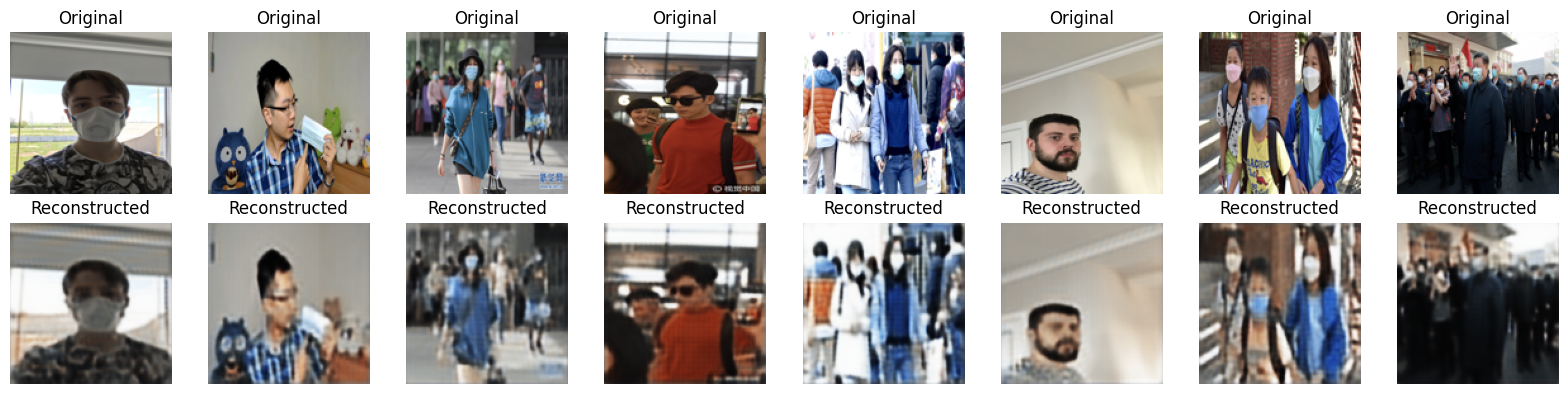

In [ ]:
model.eval()

(images,) = next(iter(val_loader))
images = images[:8].to(device)

with torch.no_grad():
    # Use mu for deterministic reconstruction during this visualization
    mu, logvar = model.encoder(images)
    reconstructed = model.decoder(mu)

original = images.cpu().permute(0, 2, 3, 1).numpy()
reconstructed = reconstructed.cpu().permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(original[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].clip(0, 1))
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

Intresting observation changing beta_vae values changed colours of predicted images



VAE ends and diffusion starts

In [ ]:
z.shape

torch.Size([22, 4, 32, 32])

In [ ]:
T = 200

betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = (1-betas)
alpha_bar = torch.cumprod(alphas, dim=0)
epsilon = torch.randn_like(z)

t = torch.randint(0, T, (z.shape[0],)) # for 32 diffirent values you select 32 different time steps

alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)

z_t = (
    torch.sqrt(alpha_bar_t) * z
    + torch.sqrt(1 - alpha_bar_t) * epsilon
)


In [ ]:
print("Initial alpha_bar:", alpha_bar[0].item())
print("Final alpha_bar:", alpha_bar[-1].item())

Initial alpha_bar: 0.9998999834060669
Final alpha_bar: 0.132182776927948


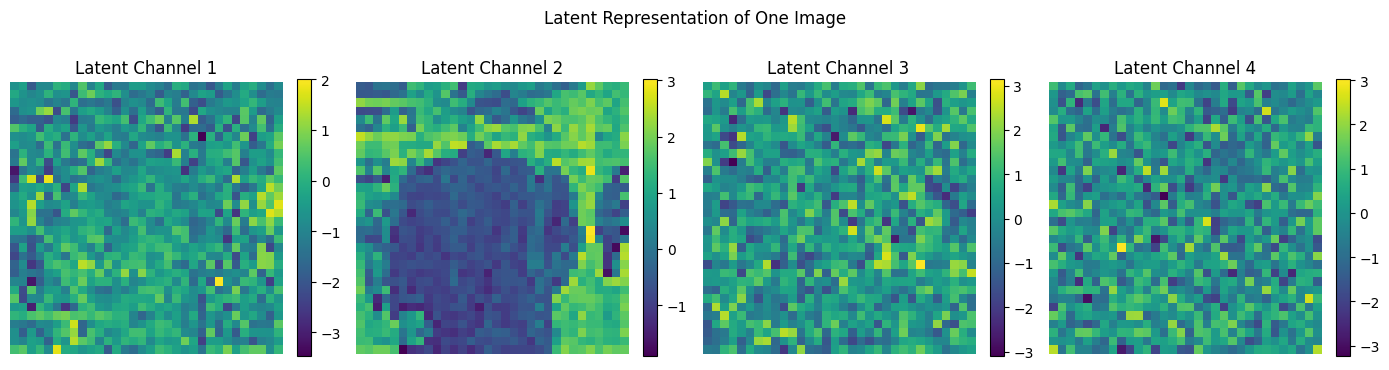

In [ ]:
import matplotlib.pyplot as plt
import torch

# Take the first image in the batch
latent = z[0].detach().cpu()

fig, axes = plt.subplots(1, latent.shape[0], figsize=(14, 4))

for i in range(latent.shape[0]):
    im = axes[i].imshow(latent[i], cmap="viridis")
    axes[i].set_title(f"Latent Channel {i + 1}")
    axes[i].axis("off")
    plt.colorbar(im, ax=axes[i], fraction=0.046)

plt.suptitle("Latent Representation of One Image")
plt.tight_layout()
plt.show()

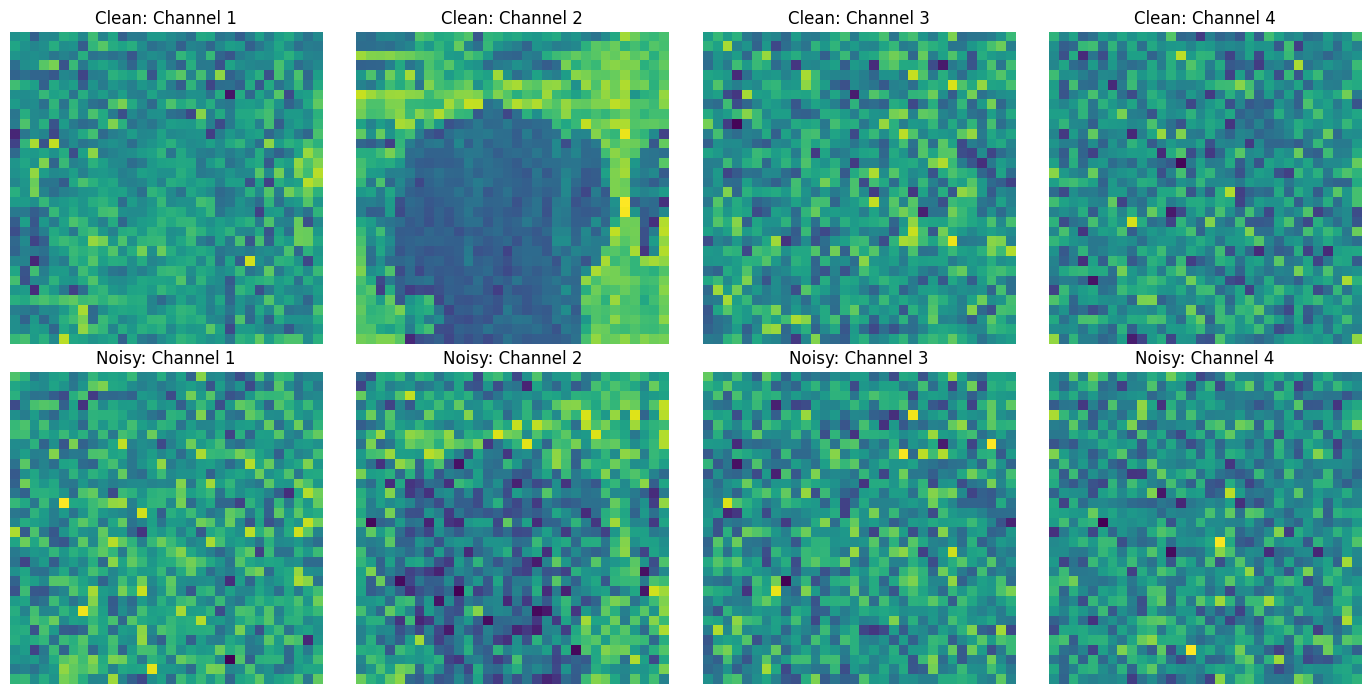

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

z0 = z[0].detach().cpu()
zt = z_t[0].detach().cpu()

# Use the same color scale for each corresponding channel
for i in range(4):
    vmin = min(z0[i].min().item(), zt[i].min().item())
    vmax = max(z0[i].max().item(), zt[i].max().item())

    axes[0, i].imshow(z0[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[0, i].set_title(f"Clean: Channel {i+1}")

    axes[1, i].imshow(zt[i], cmap="viridis", vmin=vmin, vmax=vmax)
    axes[1, i].set_title(f"Noisy: Channel {i+1}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
z_t.shape

torch.Size([22, 4, 32, 32])

From here iam starting denoising process

In [ ]:
#This is a acrhitectural choice to represent the timestamps in a rich way
# i will also try just normalizing the timestamps and directly adding them to z_t and check the results

dim = 128
half_dim  = dim/2
frequencies = torch.exp(
    -math.log(10000) *
    torch.arange(half_dim, device=t.device).float()
    / (half_dim - 1)
)



In [ ]:
angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

In [ ]:
angles.shape

torch.Size([22, 64])

In [ ]:
time_embd = torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1)

In [ ]:
time_embd.shape

torch.Size([22, 128])

In [ ]:
z_t.shape

torch.Size([22, 4, 32, 32])

In [ ]:
class noise_pred_model(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv_in = nn.Conv2d(4, 64, kernel_size=3, padding=1, device=device)
    self.time_mlp = nn.Sequential(
            nn.Linear(128, 128),
            nn.SiLU(),
            nn.Linear(128, 64)
        )

    self.conv_mid = nn.Sequential(
                nn.SiLU(),
                nn.Conv2d(64, 64, 3, padding=1),
                nn.SiLU(),
                nn.Conv2d(64, 64, 3, padding=1)
            ).to(device)
    self.conv_out = nn.Conv2d(64, 4, 3, padding=1, device=device)

  def forward(self, z_t, time_embd):
    # Ensure input tensors are on the correct device
    time_embd = time_embd.to(device)
    z_t = z_t.to(device)
    projected_time = self.time_mlp(time_embd)
    h = self.conv_in(z_t)
    h = h + projected_time[:, :, None, None]
    h = self.conv_mid(h)
    noise_pred = self.conv_out(h)
    return noise_pred

In [ ]:
noise_pred_ = noise_pred_model()

In [ ]:
# 1. Instantiate the model and move it to the correct device
model_diffusion = noise_pred_model().to(device)

# 2. Forward pass with inputs on the correct device
# (z_t, time_embd, and epsilon should already be defined)
noise_pred_tensor = model_diffusion(z_t.to(device), time_embd.to(device))

# 3. Compute loss
loss = F.mse_loss(noise_pred_tensor, epsilon.to(device))
print("Loss:", loss.item())

Loss: 0.9993207454681396


Trainig the noise prediction model

In [ ]:
import math
import torch
import torch.nn.functional as F

#this tarins the VAE on encoder and decoder

# Keep the trained VAE frozen
vae.eval()

for param in vae.parameters():
    param.requires_grad_(False)

# Create the denoising model
denoiser = noise_pred_model().to(device)

optimizer = torch.optim.AdamW(
    denoiser.parameters(),
    lr=1e-4
)

T = 200
num_epochs = 50


# Sinusoidal timestep embeddings
def sinusoidal_embedding(t, dim=128):
    half_dim = dim // 2

    frequencies = torch.exp(
        -math.log(10000.0)
        * torch.arange(
            half_dim, device=t.device, dtype=torch.float32
        ) / (half_dim - 1)
    )

    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

    return torch.cat(
        [torch.sin(angles), torch.cos(angles)],
        dim=1
    )


# Train the denoiser
for epoch in range(num_epochs):

    denoiser.train()
    total_loss = 0.0
    total_images = 0

    for (images,) in train_loader:

        images = images.to(device)

        # 1. Encode this batch using the trained VAE
        with torch.no_grad():
            mu, logvar = vae.encoder(images)

            z0 = (
                mu
                + torch.exp(0.5 * logvar)
                * torch.randn_like(logvar)
            )

        # 2. Sample fresh Gaussian noise
        epsilon = torch.randn_like(z0)

        # 3. Sample a timestep for each image


        t = torch.randint(
            0, T,
            (images.shape[0],),
            device=device
        )

        # 4. Construct the noisy latent
        alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)

        z_t = (
            torch.sqrt(alpha_bar_t) * z0
            + torch.sqrt(1 - alpha_bar_t) * epsilon
        )

        # 5. Embed the timesteps
        time_embd = sinusoidal_embedding(t, dim=128)

        # 6. Predict the noise
        predicted_noise = denoiser(z_t, time_embd)

        # 7. Compare against the actual noise
        loss = F.mse_loss(predicted_noise, epsilon)

        # 8. Update denoiser weights
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        batch_size = images.shape[0]
        total_loss += loss.item() * batch_size
        total_images += batch_size

    avg_loss = total_loss / total_images

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {avg_loss:.6f}"
    )

# Save trained denoiser weights
torch.save(denoiser.state_dict(), "denoiser.pth")

Epoch [1/50] Loss: 0.975336
Epoch [2/50] Loss: 0.897172
Epoch [3/50] Loss: 0.767092
Epoch [4/50] Loss: 0.649085
Epoch [5/50] Loss: 0.593077
Epoch [6/50] Loss: 0.604831
Epoch [7/50] Loss: 0.588256
Epoch [8/50] Loss: 0.577718
Epoch [9/50] Loss: 0.581724
Epoch [10/50] Loss: 0.601875
Epoch [11/50] Loss: 0.587407
Epoch [12/50] Loss: 0.578862
Epoch [13/50] Loss: 0.566419
Epoch [14/50] Loss: 0.566968
Epoch [15/50] Loss: 0.578442
Epoch [16/50] Loss: 0.588818
Epoch [17/50] Loss: 0.585831
Epoch [18/50] Loss: 0.578106
Epoch [19/50] Loss: 0.572188
Epoch [20/50] Loss: 0.568318
Epoch [21/50] Loss: 0.538334
Epoch [22/50] Loss: 0.561948
Epoch [23/50] Loss: 0.573469
Epoch [24/50] Loss: 0.568355
Epoch [25/50] Loss: 0.567595
Epoch [26/50] Loss: 0.575815
Epoch [27/50] Loss: 0.565100
Epoch [28/50] Loss: 0.587975
Epoch [29/50] Loss: 0.559799
Epoch [30/50] Loss: 0.588164
Epoch [31/50] Loss: 0.571614
Epoch [32/50] Loss: 0.572282
Epoch [33/50] Loss: 0.557691
Epoch [34/50] Loss: 0.565805
Epoch [35/50] Loss: 0.5

##This is the end of pretrainig and from here i have to start inference part

### Diffusion Noise Schedule

The variance schedule is defined as:

$$
\beta_t \in (0,1)
$$

The corresponding alpha value is:

$$
\alpha_t = 1 - \beta_t
$$

The cumulative product of alpha values is:

$$
\bar{\alpha}_t = \prod_{s=1}^{t} \alpha_s
$$

### Reverse Diffusion Mean

The mean of the reverse transition distribution is:

$$
\mu_\theta(z_t,t) =
\frac{1}{\sqrt{\alpha_t}}
\left(
z_t -
\frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}
\epsilon_\theta(z_t,t)
\right)
$$

where $\epsilon_\theta(z_t,t)$ is the noise predicted by the denoising model.

### Reverse Diffusion Variance

The posterior variance is:

$$
\tilde{\beta}_t =
\beta_t
\frac{1-\bar{\alpha}_{t-1}}
{1-\bar{\alpha}_t}
$$

### Reverse Sampling Step

For $t > 0$, sample the previous latent using:

$$
z_{t-1} =
\mu_\theta(z_t,t)
+
\sqrt{\tilde{\beta}_t}\,\xi
$$

where:

$$
\xi \sim \mathcal{N}(0,I)
$$

At $t=0$, use the calculated mean without adding extra noise.

In [ ]:
betas.shape

torch.Size([200])

In [ ]:
alpha_bar_t.shape

torch.Size([31, 1, 1, 1])

In [ ]:
# we can also approxiamate z0 final no noise image from this in one step

# z0_pred1 = (
#     z_t - torch.sqrt(1 - alpha_bar_t) * noise_pred_tensor
# ) / torch.sqrt(alpha_bar_t).to(device)

# # we will not use this as its unstable




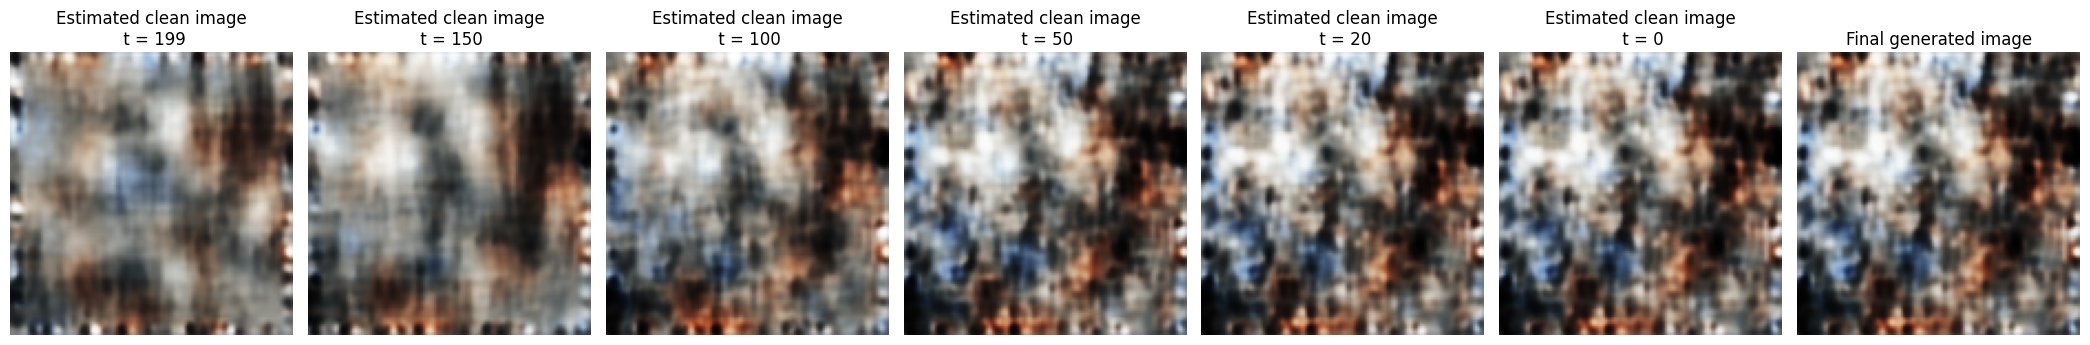

In [ ]:
import torch
import matplotlib.pyplot as plt

# Evaluation mode
denoiser.eval()
vae.eval()

T = len(betas)
num_images = 1

# Checkpoints at which we want to visualize the image estimate
snapshot_steps = [199, 150, 100, 50, 20, 0]
snapshots = []

# Start with random latent noise
z = torch.randn(
    num_images, 4, 32, 32,
    device=device
)

with torch.no_grad():

    for i in reversed(range(T)):

        # 1. Tell the denoiser the CURRENT timestep
        t = torch.full(
            (num_images,),
            i,
            dtype=torch.long,
            device=device
        )

        time_embd = sinusoidal_embedding(t, dim=128)

        # 2. Predict noise in the current latent
        predicted_noise = denoiser(z, time_embd)

        beta_t = betas[i]
        alpha_t = alphas[i]
        alpha_bar_t = alpha_bar[i]

        # 3. Estimate the original clean latent z0
        z0_pred = (
            z - torch.sqrt(1 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        # 4. Save a decoded estimate at selected timesteps
        if i in snapshot_steps:
            estimated_image = vae.decoder(z0_pred)

            snapshots.append((
                i,
                estimated_image[0].cpu().clamp(0, 1)
            ))

        # 5. Calculate the reverse mean
        mu_theta = (
            z - (beta_t / torch.sqrt(1 - alpha_bar_t))
            * predicted_noise
        ) / torch.sqrt(alpha_t)

        # 6. Sample the previous latent
        if i > 0:
            variance = (
                beta_t * (1 - alpha_bar[i - 1])
                / (1 - alpha_bar_t)
            )

            z = (
                mu_theta
                + torch.sqrt(variance.clamp(min=1e-20))
                * torch.randn_like(z)
            )
        else:
            z = mu_theta

    # Decode the final latent after completing reverse diffusion
    final_image = vae.decoder(z)[0].cpu().clamp(0, 1)

# 7. Display the denoising progression
fig, axes = plt.subplots(
    1, len(snapshots) + 1,
    figsize=(3 * (len(snapshots) + 1), 4)
)

for ax, (timestep, image) in zip(axes, snapshots):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f"Estimated clean image\n t = {timestep}")
    ax.axis("off")

axes[-1].imshow(final_image.permute(1, 2, 0))
axes[-1].set_title("Final generated image")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

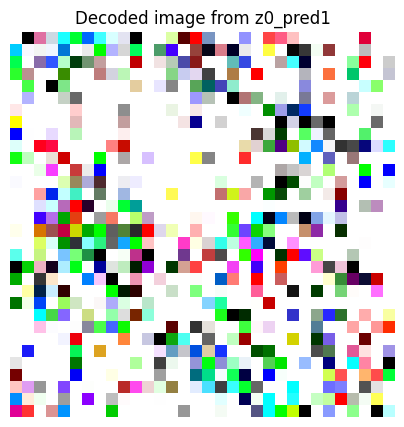

In [ ]:
import matplotlib.pyplot as plt

img = generated_z[0].detach().cpu().permute(1, 2, 0)

# If the decoder outputs values in [0, 1]
img = img.clamp(0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Decoded image from z0_pred1")
plt.show()